In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED, is_higher_better, get_metric_abbr, get_metric_label

In [4]:
dataset = build_dataset('test')

In [5]:
unet_baseline = ModelResults('107-deeplabv3plus', 'unet', 199, 'test', dataset)
ddpm_1000 = ModelResults('112-beamdiff-bf16', 'ddpm-1000', 199, 'test', dataset)
ddpm_500 = ModelResults('112-beamdiff-bf16', 'ddpm-500', 199, 'test', dataset)
ddpm_100 = ModelResults('112-beamdiff-bf16', 'ddpm-100', 199, 'test', dataset)
ddpm_50 = ModelResults('112-beamdiff-bf16', 'ddpm-50', 199, 'test', dataset)
ddpm_10 = ModelResults('112-beamdiff-bf16', 'ddpm-10', 199, 'test', dataset)
ddpm_5 = ModelResults('112-beamdiff-bf16', 'ddpm-5', 199, 'test', dataset)
ddpm_1 = ModelResults('112-beamdiff-bf16', 'ddpm-1', 199, 'test', dataset)

In [6]:
flow_1000 = ModelResults('140-rfm', 'flow-1000', 199, 'test', dataset)
flow_500 = ModelResults('140-rfm', 'flow-500', 199, 'test', dataset)
flow_100 = ModelResults('140-rfm', 'flow-100', 199, 'test', dataset)
flow_50 = ModelResults('140-rfm', 'flow-50', 199, 'test', dataset)
flow_10 = ModelResults('140-rfm', 'flow-10', 199, 'test', dataset)
flow_5 = ModelResults('140-rfm', 'flow-5', 199, 'test', dataset)
flow_4 = ModelResults('140-rfm', 'flow-4', 199, 'test', dataset)
flow_3 = ModelResults('140-rfm', 'flow-3', 199, 'test', dataset)
flow_2 = ModelResults('140-rfm', 'flow-2', 199, 'test', dataset)
flow_1 = ModelResults('140-rfm', 'flow-1', 199, 'test', dataset)

In [7]:
flow_comparison = ModelComparison(
  [flow_1000, flow_500, flow_100, flow_50, flow_10, flow_5, flow_4, flow_3, flow_2, flow_1],
  ['T=1000', 'T=500', 'T=100', 'T=50', 'T=10', 'T=5', 'T=4', 'T=3', 'T=2', 'T=1']
)

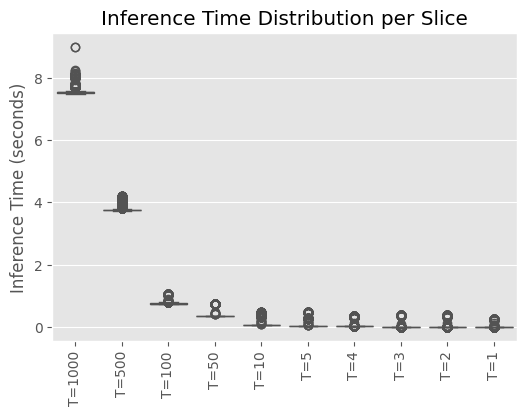

In [8]:
_ = flow_comparison.plot_inference_times('slice', 'seconds')

/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore 

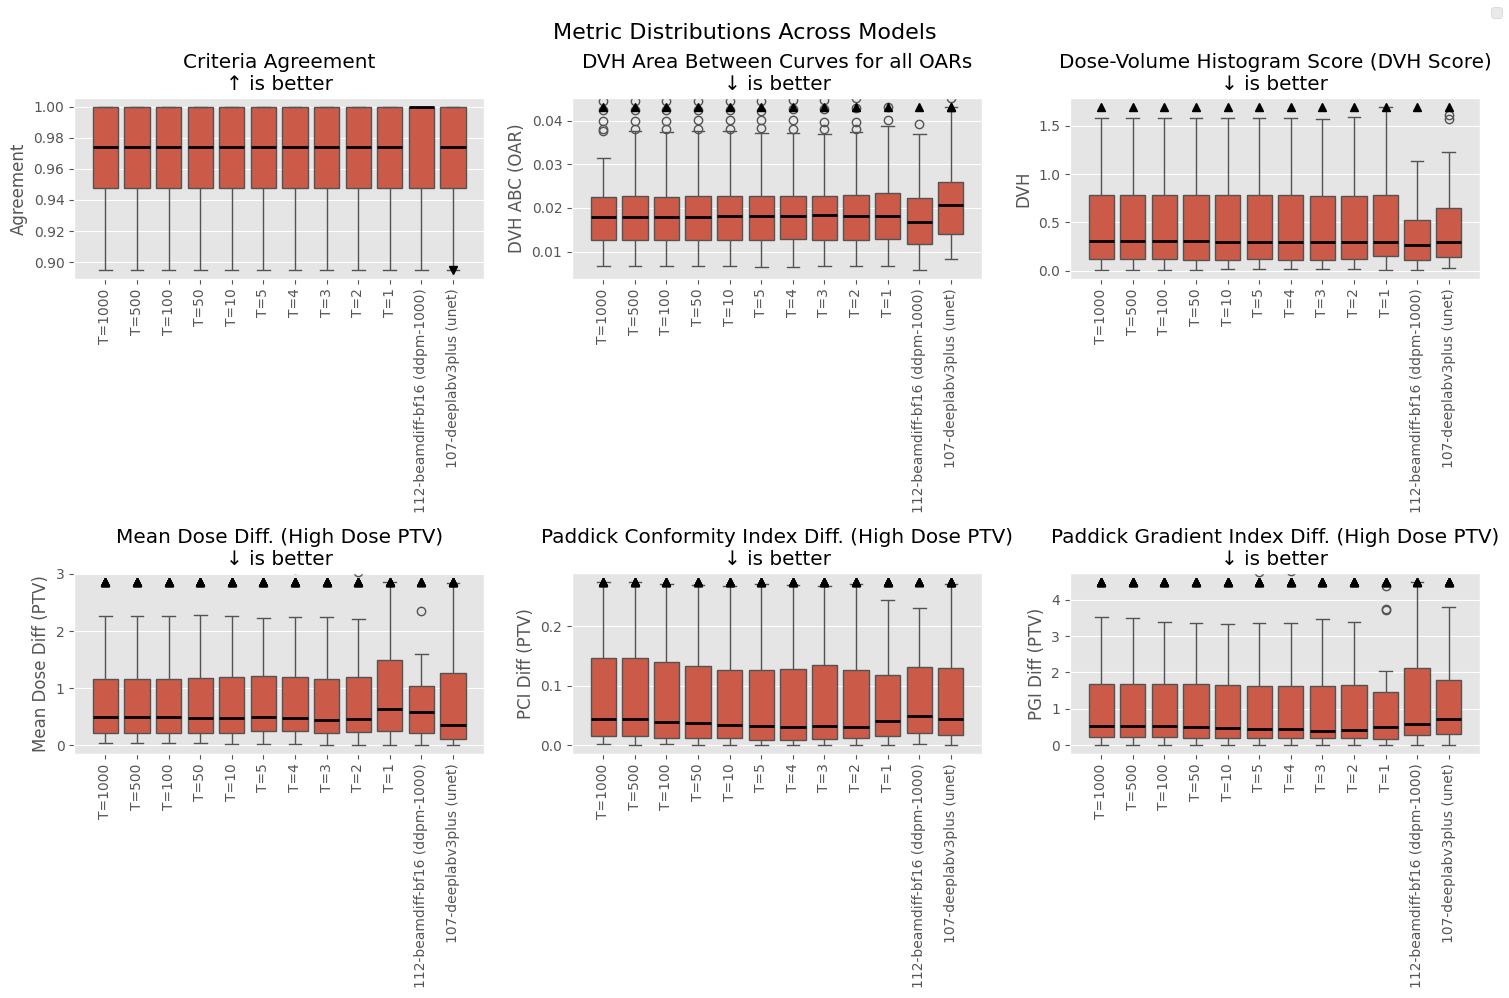

In [9]:
_ = (flow_comparison + ddpm_1000 + unet_baseline).plot_metric_distributions(METRICS_PRED, outliers=False)

/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')


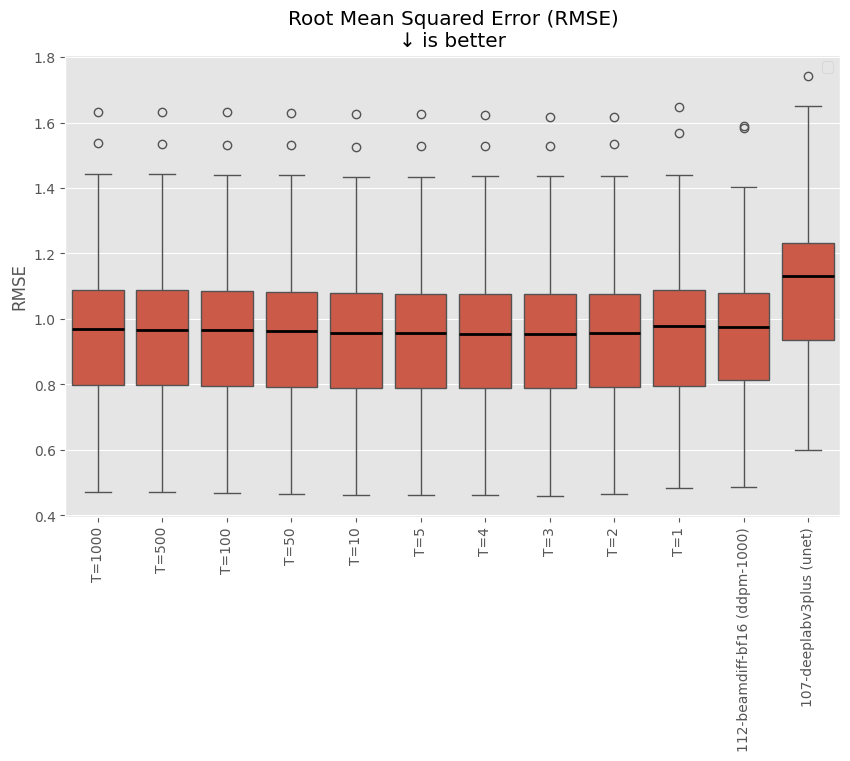

In [10]:
_ = (flow_comparison + ddpm_1000 + unet_baseline).plot_metric_distribution('vol_rmse')

## Warm-Start with U-Net

In [12]:
flow_unet_100 = ModelResults('145-rfm-deeplabv3plus', 'flow-100', 199, 'test', dataset)
flow_unet_50 = ModelResults('145-rfm-deeplabv3plus', 'flow-50', 199, 'test', dataset)
flow_unet_10 = ModelResults('145-rfm-deeplabv3plus', 'flow-10', 199, 'test', dataset)
flow_unet_5 = ModelResults('145-rfm-deeplabv3plus', 'flow-5', 199, 'test', dataset)
flow_unet_4 = ModelResults('145-rfm-deeplabv3plus', 'flow-4', 199, 'test', dataset)
flow_unet_3 = ModelResults('145-rfm-deeplabv3plus', 'flow-3', 199, 'test', dataset)
flow_unet_2 = ModelResults('145-rfm-deeplabv3plus', 'flow-2', 199, 'test', dataset)
flow_unet_1 = ModelResults('145-rfm-deeplabv3plus', 'flow-1', 199, 'test', dataset)

In [13]:
flow_unet_comparison = ModelComparison(
  [flow_unet_100, flow_unet_50, flow_unet_10, flow_unet_5, flow_unet_4, flow_unet_3, flow_unet_2, flow_unet_1],
  ['T=100', 'T=50', 'T=10', 'T=5', 'T=4', 'T=3', 'T=2', 'T=1']
)

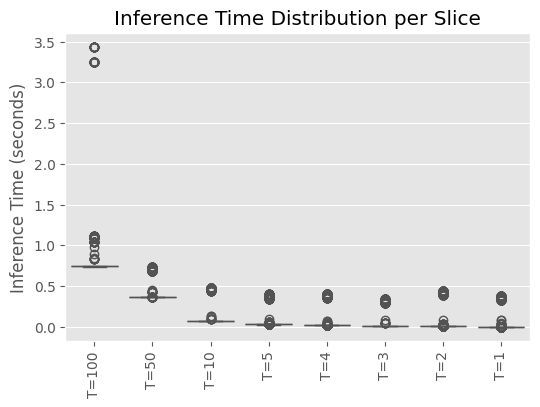

In [14]:
_ = flow_unet_comparison.plot_inference_times('slice', 'seconds')

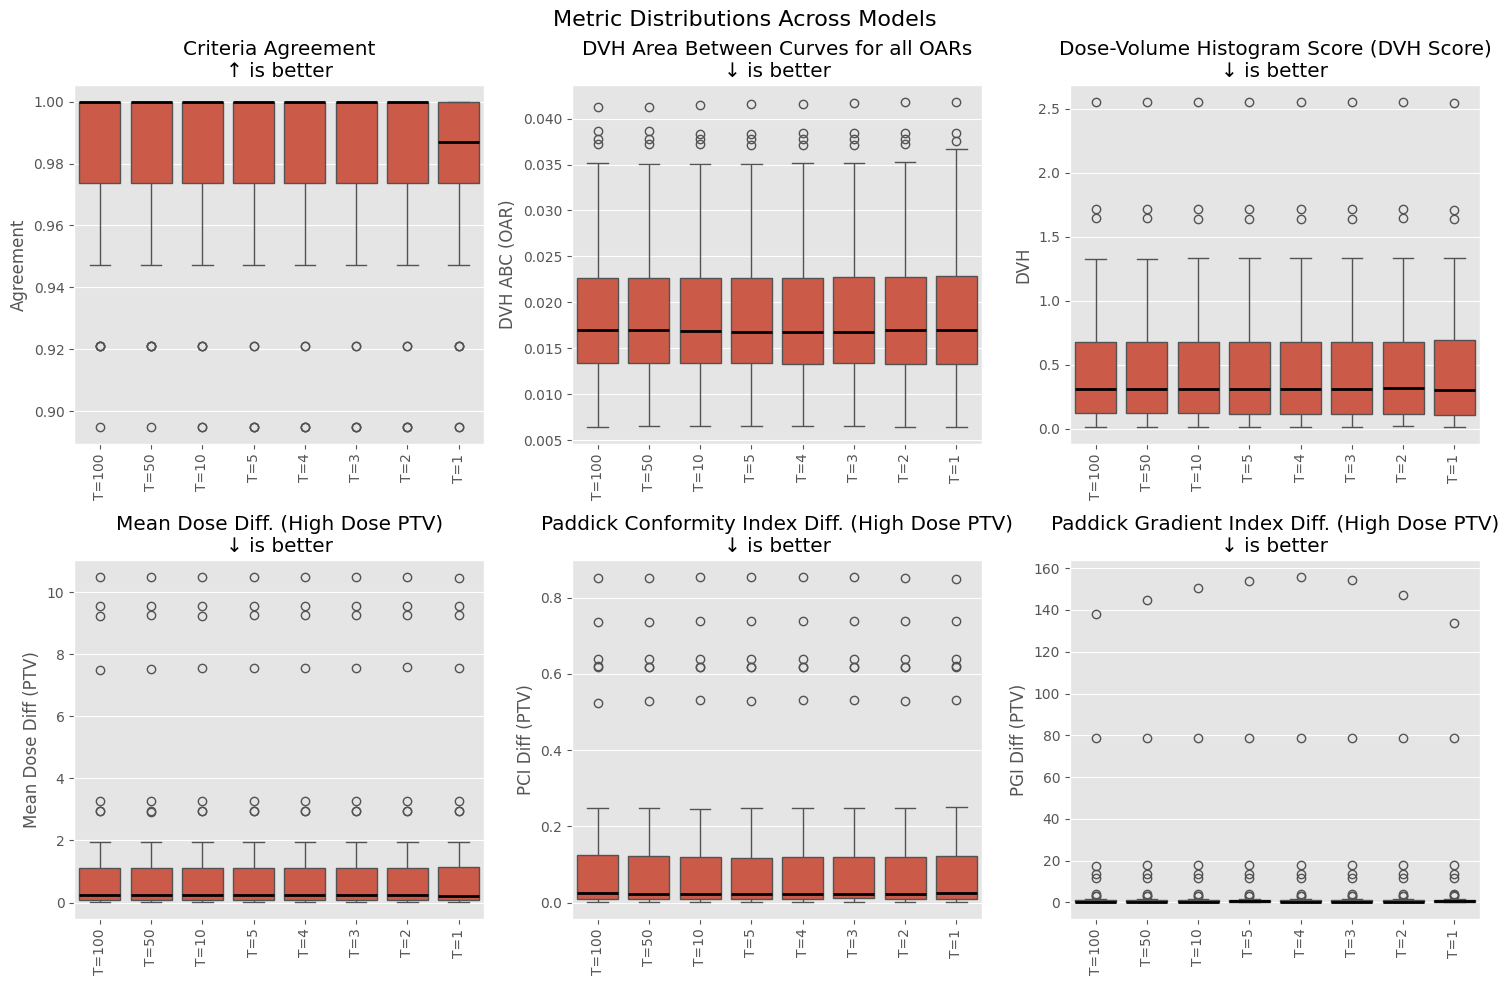

In [15]:
_ = flow_unet_comparison.plot_metric_distributions(METRICS_PRED, outliers=True)

## Warm-Start with Analytical Dose

In [17]:
flow_ad_100 = ModelResults('146-rfm-analytical-dose', 'flow-100', 199, 'test', dataset)
flow_ad_50 = ModelResults('146-rfm-analytical-dose', 'flow-50', 199, 'test', dataset)
flow_ad_10 = ModelResults('146-rfm-analytical-dose', 'flow-10', 199, 'test', dataset)
flow_ad_5 = ModelResults('146-rfm-analytical-dose', 'flow-5', 199, 'test', dataset)
flow_ad_4 = ModelResults('146-rfm-analytical-dose', 'flow-4', 199, 'test', dataset)
flow_ad_3 = ModelResults('146-rfm-analytical-dose', 'flow-3', 199, 'test', dataset)
flow_ad_2 = ModelResults('146-rfm-analytical-dose', 'flow-2', 199, 'test', dataset)
flow_ad_1 = ModelResults('146-rfm-analytical-dose', 'flow-1', 199, 'test', dataset)

In [18]:
flow_ad_comparison = ModelComparison(
  [flow_ad_100, flow_ad_50, flow_ad_10, flow_ad_5, flow_ad_4, flow_ad_3, flow_ad_2, flow_ad_1],
  ['T=100', 'T=50', 'T=10', 'T=5', 'T=4', 'T=3', 'T=2', 'T=1']
)

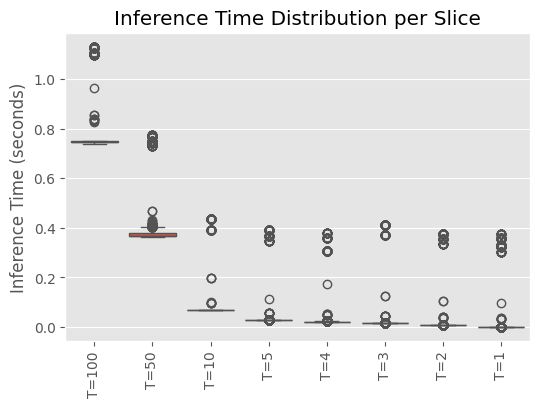

In [19]:
_ = flow_ad_comparison.plot_inference_times('slice', 'seconds')

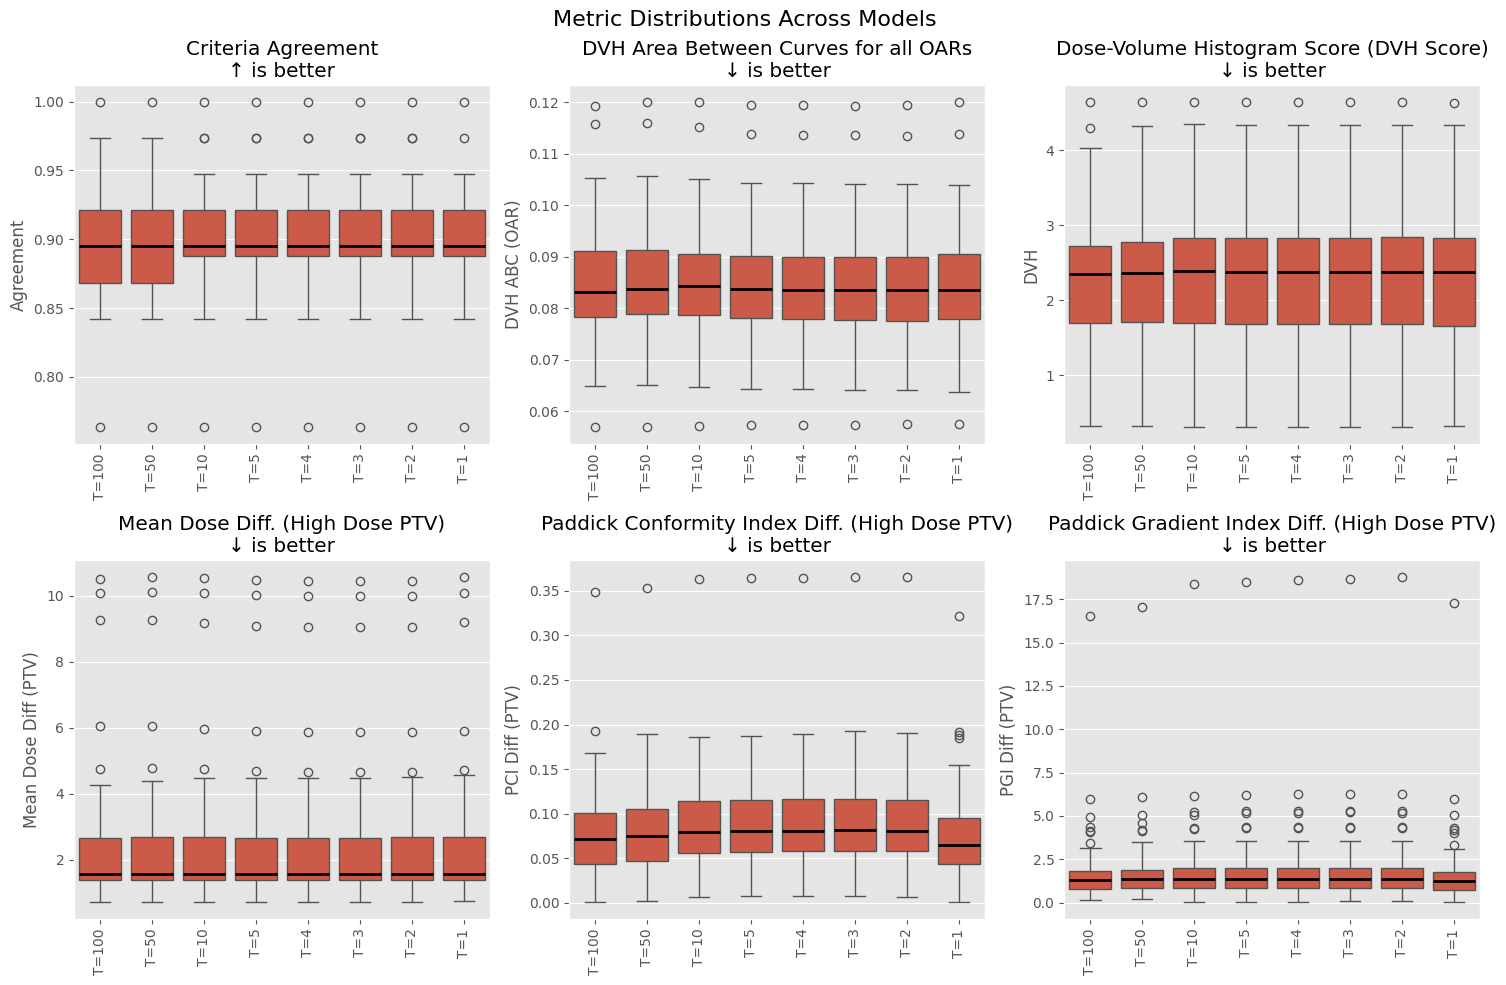

In [20]:
_ = flow_ad_comparison.plot_metric_distributions(METRICS_PRED, outliers=True)